[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/09_Redes_Residuais.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**TCE11616 - Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 09 — REDES RESIDUAIS
---

Na prática, percebeu-se que redes muito profundas podem para de aprender (uma rede com 50 camadas poderia ter desempenho pior que uma rede com 2 camadas). 


A solução, proposta em 2015, é surpreendentemente simples: um **atalho** que soma a entrada de cada bloco à sua saída. 

As redes construídas assim se chamam **redes residuais** (ResNets) e são a base de praticamente todas as redes profundas modernas, inclusive dos Transformers (próxima aula).

> **Dica:** no Colab, use GPU (*Ambiente de execução → Alterar o tipo de ambiente de execução*). Em CPU, a aula leva cerca de 1 minuto, mais o download dos dados.

## 0. Importando as bibliotecas

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

from torch.utils.data import TensorDataset, DataLoader

---
## 1. O problema: redes muito profundas não aprendem
---

Usaremos o conjunto **digits** do scikit-learn (imagens $8 \times 8$ de dígitos). Ele é pequeno, então conseguimos treinar redes de 50 camadas em poucos segundos.

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digitos = load_digits()
X_tr, X_te, y_tr, y_te = train_test_split(digitos.data, digitos.target, test_size=0.3, random_state=42)

X_treino = torch.tensor(X_tr / 16, dtype=torch.float32)
X_teste  = torch.tensor(X_te / 16, dtype=torch.float32)
Y_treino = torch.tensor(y_tr, dtype=torch.long)
Y_teste  = torch.tensor(y_te, dtype=torch.long)

carregador = DataLoader(TensorDataset(X_treino, Y_treino), batch_size=64, shuffle=True)
print("treino:", X_treino.shape, "| teste:", X_teste.shape)

treino: torch.Size([1257, 64]) | teste: torch.Size([540, 64])


Vamos criar abaixo uma função que treina qualquer modelo por 20 épocas e devolve a acurácia no teste:

In [3]:
def treinar_e_avaliar(modelo, epocas=20):
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    for epoca in range(epocas):
        modelo.train()
        for xb, yb in carregador:
            perda = perda_fn(modelo(xb), yb)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
    modelo.eval()
    with torch.no_grad():
        return (modelo(X_teste).argmax(dim=1) == Y_teste).float().mean().item()

Agora, uma função que monta uma rede **comum** com quantas camadas ocultas quisermos (todas com 32 neurônios):

In [4]:
def rede_comum(n_camadas):
    camadas = [nn.Linear(64, 32), nn.ReLU()]
    for i in range(n_camadas):
        camadas.append(nn.Linear(32, 32))
        camadas.append(nn.ReLU())
    camadas.append(nn.Linear(32, 10))
    return nn.Sequential(*camadas)


for n in [2, 10, 30, 50]:
    torch.manual_seed(42)
    acc = treinar_e_avaliar(rede_comum(n))
    print(f"rede comum com {n:2d} camadas: acurácia no teste = {acc:.1%}")

rede comum com  2 camadas: acurácia no teste = 90.4%
rede comum com 10 camadas: acurácia no teste = 63.9%
rede comum com 30 camadas: acurácia no teste = 8.0%
rede comum com 50 camadas: acurácia no teste = 9.8%


Com 2 camadas, tudo bem. Com 10, a acurácia já piora bastante. Com 30 ou 50 camadas, ela cai para cerca de **10%**, o mesmo que chutar um dígito ao acaso entre 10. A rede **não aprendeu nada**.

**Por quê?** Lembre da Aula 05: o gradiente (o "sinal" que diz como corrigir cada peso) é calculado de trás para frente, passando por todas as camadas. A cada camada ele é multiplicado por novos números e, depois de dezenas de camadas, praticamente **some**. As primeiras camadas não recebem nenhuma orientação para melhorar.

---
## 2. A solução: um atalho
---

Em uma rede comum, cada bloco **substitui** o que recebeu:

$$ \text{saída} = f(x) $$

Em uma rede **residual**, cada bloco **soma** uma correção ao que recebeu:

$$ \text{saída} = x + f(x) $$

```
         ┌────────── atalho ──────────┐
         │                            ▼
  x ─────┴──→ [ Linear → ReLU ] ──→ ( + ) ──→ saída
                    f(x)
```

Duas consequências:

- **o bloco só precisa aprender uma correção** $f(x)$ (o "resíduo"); se ele não tiver nada útil a acrescentar, basta aprender $f(x) \approx 0$ e a informação passa adiante intacta;
- **o gradiente também passa pelo atalho**, chegando às primeiras camadas sem se perder.

### Escrevendo nossa primeira classe de rede

O `nn.Sequential` só sabe encadear peças em fila. Para fazer a soma do atalho, precisamos descrever o caminho dos dados nós mesmos. Fazemos isso criando uma **classe** que herda de `nn.Module`. Ela tem sempre duas partes:

- **`__init__`**: cria as peças do bloco (as camadas com parâmetros);
- **`forward`**: diz como os dados passam pelas peças.

In [5]:
class BlocoResidual(nn.Module):
    def __init__(self, largura):
        super().__init__()                     # linha obrigatória em toda classe de rede
        self.linear = nn.Linear(largura, largura)
        self.ativacao = nn.ReLU()

    def forward(self, x):
        correcao = self.ativacao(self.linear(x))   # f(x)
        return x + correcao                        # o atalho: x + f(x)


bloco = BlocoResidual(32)
print(bloco)
x = torch.randn(5, 32)
print("entrada:", x.shape, "-> saída:", bloco(x).shape)    # o formato não muda

BlocoResidual(
  (linear): Linear(in_features=32, out_features=32, bias=True)
  (ativacao): ReLU()
)
entrada: torch.Size([5, 32]) -> saída: torch.Size([5, 32])


Um objeto dessa classe se comporta como qualquer camada do PyTorch: podemos colocá-lo dentro de um `nn.Sequential`, e o PyTorch encontra os parâmetros sozinho.

In [6]:
def rede_residual(n_blocos, Bloco=BlocoResidual):
    camadas = [nn.Linear(64, 32), nn.ReLU()]
    for i in range(n_blocos):
        camadas.append(Bloco(32))
    camadas.append(nn.Linear(32, 10))
    return nn.Sequential(*camadas)


for n in [2, 10, 30, 50]:
    torch.manual_seed(42)
    acc = treinar_e_avaliar(rede_residual(n))
    print(f"rede residual com {n:2d} blocos: acurácia no teste = {acc:.1%}")

rede residual com  2 blocos: acurácia no teste = 94.8%
rede residual com 10 blocos: acurácia no teste = 95.7%
rede residual com 30 blocos: acurácia no teste = 89.4%
rede residual com 50 blocos: acurácia no teste = 49.8%


Com o atalho, a rede de 30 camadas volta a aprender bem. Mas com 50 blocos ainda há problema: como cada bloco **soma** algo à entrada, os valores vão crescendo bloco após bloco e o treino fica instável. Falta uma peça.

---
## 3. A normalização por lote (BatchNorm)
---

Na Aula 06 padronizamos os dados de entrada com o `StandardScaler` (média 0, desvio 1), porque números em escalas muito diferentes atrapalham o treino. A **normalização por lote** (*batch normalization*) faz a mesma coisa **dentro da rede**: a cada lote, ela padroniza as saídas de uma camada.

In [7]:
bn = nn.BatchNorm1d(3)

lote = torch.tensor([[100., 0.1, -5.],
                     [200., 0.3, -7.],
                     [300., 0.2, -6.]])

print("antes  - média por coluna:", lote.mean(dim=0))
saida = bn(lote)
print("depois - média por coluna:", saida.mean(dim=0).detach().round(decimals=2))
print("depois - desvio por coluna:", saida.std(dim=0, unbiased=False).detach().round(decimals=2))

antes  - média por coluna: tensor([200.0000,   0.2000,  -6.0000])
depois - média por coluna: tensor([-0., 0., -0.])
depois - desvio por coluna: tensor([1., 1., 1.])


> Assim como o dropout (Aula 07), a BatchNorm se comporta de forma diferente em `modelo.train()` e `modelo.eval()`: no treino, ela usa a média e o desvio do lote atual; na avaliação, usa médias acumuladas durante o treino. Mais um motivo para nunca esquecer essas duas linhas.

Colocamos a BatchNorm dentro do bloco residual, logo depois da camada linear. Esta é a receita usada nas ResNets de verdade:

In [8]:
class BlocoResidualBN(nn.Module):
    def __init__(self, largura):
        super().__init__()
        self.linear = nn.Linear(largura, largura)
        self.norma = nn.BatchNorm1d(largura)
        self.ativacao = nn.ReLU()

    def forward(self, x):
        correcao = self.ativacao(self.norma(self.linear(x)))
        return x + correcao


for n in [2, 10, 30, 50]:
    torch.manual_seed(42)
    acc = treinar_e_avaliar(rede_residual(n, Bloco=BlocoResidualBN))
    print(f"rede residual + BatchNorm com {n:2d} blocos: acurácia no teste = {acc:.1%}")

rede residual + BatchNorm com  2 blocos: acurácia no teste = 97.8%
rede residual + BatchNorm com 10 blocos: acurácia no teste = 97.2%
rede residual + BatchNorm com 30 blocos: acurácia no teste = 95.6%
rede residual + BatchNorm com 50 blocos: acurácia no teste = 93.1%


Agora até a rede de 50 blocos treina sem problemas.

Neste problema pequeno, 50 camadas não são necessárias: uma rede com 2 camadas já resolve bem. 

Lição: **atalhos + normalização** permitem treinar redes muito profundas, e é isso que possibilita os modelos gigantes usados hoje em imagens e em texto.

---
## 4. Uma ResNet de verdade
---

O `torchvision` traz ResNets prontas. A **ResNet-18** tem 18 camadas convolucionais organizadas em blocos residuais, cada um com convolução, BatchNorm, ReLU e o atalho, exatamente como fizemos (só que com `nn.Conv2d` e `nn.BatchNorm2d`, já que trabalha com imagens).

In [9]:
from torchvision import models

resnet = models.resnet18()
print("parâmetros:", sum(p.numel() for p in resnet.parameters()))
print()
print(resnet.layer1[0])      # um dos blocos residuais

parâmetros: 11689512

BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)


São mais de **11 milhões** de parâmetros. Treinar uma rede dessas do zero exige muitos dados e muitas horas de GPU. A boa notícia: não precisamos fazer isso.

---
## 5. Usando uma ResNet já treinada (*transfer learning*)
---

Existem versões da ResNet-18 já treinadas no **ImageNet**, um conjunto com mais de 1 milhão de fotos de 1 000 categorias. Para reconhecer tantas coisas, essas redes aprenderam filtros muito úteis: bordas, texturas, formas, partes de objetos... 

A ideia do *transfer learning* (aprendizado por transferência):

1. pegar a rede já treinada e **remover a última camada** (a que decidia entre as 1000 categorias do ImageNet);
2. usar o resto da rede como um **extrator de características**: cada imagem vira um vetor de 512 números;
3. treinar só uma camada **nova e pequena** (`nn.Linear(512, n_classes)`) para o nosso problema.

Isso funciona muito bem quando temos **poucas imagens rotuladas**, situação comum na indústria (por exemplo, poucas fotos de peças defeituosas).

### Conjunto de dados EuroSAT

O **EuroSAT** tem 27000 imagens de satélite coloridas, de $64 \times 64$ pixels, em 10 classes de uso do solo (floresta, rio, rodovia, área industrial...). Vamos fingir que temos apenas **1000** imagens rotuladas para treinar.

In [11]:
from torchvision import datasets, transforms
from torch.utils.data import Subset

# a rede pré-treinada espera imagens padronizadas com estas médias e desvios (os do ImageNet)
preparo = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eurosat = datasets.EuroSAT(root="dados", download=True, transform=preparo)
nomes = eurosat.classes
print("total de imagens:", len(eurosat))
print("classes:", nomes)

gerador = torch.Generator().manual_seed(42)
ordem = torch.randperm(len(eurosat), generator=gerador).tolist()
teste  = Subset(eurosat, ordem[:2000])          # 2 000 imagens de teste
treino = Subset(eurosat, ordem[2000:3000])      # só 1 000 imagens de treino

100.0%


total de imagens: 27000
classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


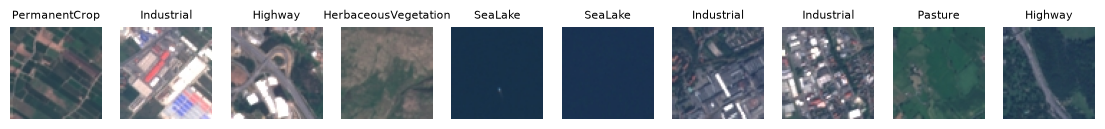

In [12]:
eurosat_original = datasets.EuroSAT(root="dados")      # sem transformação, para desenhar

plt.figure(figsize=(14, 3.2))
for i in range(10):
    imagem, rotulo = eurosat_original[ordem[2000 + i]]
    plt.subplot(1, 10, i + 1)
    plt.imshow(imagem); plt.title(nomes[rotulo], fontsize=8); plt.axis("off")
plt.show()

### Carregando a ResNet pré-treinada

O argumento `weights=...` baixa os pesos treinados no ImageNet (cerca de 45 MB). Em seguida, trocamos a última camada (`resnet.fc`) por `nn.Identity()`, uma peça que não faz nada: assim a rede devolve os 512 números de características, em vez das 1 000 categorias do ImageNet.

In [13]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print("última camada original:", resnet.fc)

resnet.fc = nn.Identity()       # remove a última camada
resnet.eval()                   # não vamos treinar a ResNet, só usá-la

with torch.no_grad():
    exemplo = resnet(torch.zeros(1, 3, 64, 64))
print("cada imagem vira um vetor de formato:", exemplo.shape)

última camada original: Linear(in_features=512, out_features=1000, bias=True)
cada imagem vira um vetor de formato: torch.Size([1, 512])


### Extraindo as características

Passamos todas as imagens de treino e de teste pela ResNet **uma única vez** e guardamos os vetores de 512 números.

> Esta célula leva cerca de 10 segundos em CPU.

In [14]:
def extrair_caracteristicas(conjunto):
    vetores, rotulos = [], []
    with torch.no_grad():
        for imagens, y in DataLoader(conjunto, batch_size=100):
            vetores.append(resnet(imagens))
            rotulos.append(y)
    return torch.cat(vetores), torch.cat(rotulos)


F_treino, Y_treino_sat = extrair_caracteristicas(treino)
F_teste,  Y_teste_sat  = extrair_caracteristicas(teste)
print("características de treino:", F_treino.shape)
print("características de teste :", F_teste.shape)

características de treino: torch.Size([1000, 512])
características de teste : torch.Size([2000, 512])


### Treinando só a última camada

Agora o problema virou uma classificação simples: 512 números de entrada, 10 classes de saída. Uma única `nn.Linear` resolve, e o treino leva menos de um segundo.

In [14]:
torch.manual_seed(42)
classificador = nn.Linear(512, 10)
perda_fn = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(classificador.parameters(), lr=0.001)

for epoca in range(300):
    perda = perda_fn(classificador(F_treino), Y_treino_sat)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

with torch.no_grad():
    acc_transfer = (classificador(F_teste).argmax(dim=1) == Y_teste_sat).float().mean().item()
print(f"ResNet pré-treinada + nova última camada: acurácia no teste = {acc_transfer:.1%}")

ResNet pré-treinada + nova última camada: acurácia no teste = 86.5%


### Comparando com uma CNN treinada do zero

Para ter uma referência, treinamos uma CNN pequena (como a da Aula 08) **do zero**, com as mesmas 1 000 imagens.

> Esta célula leva cerca de 30 segundos em CPU.

In [15]:
torch.manual_seed(42)
cnn = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 64 -> 32
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32 -> 16
    nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 -> 8
    nn.Flatten(), nn.Linear(64 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 10),
)
otimizador = torch.optim.Adam(cnn.parameters(), lr=0.001)
carregador_sat = DataLoader(treino, batch_size=32, shuffle=True)

for epoca in range(30):
    cnn.train()
    for imagens, rotulos in carregador_sat:
        perda = perda_fn(cnn(imagens), rotulos)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()

cnn.eval()
acertos = 0
with torch.no_grad():
    for imagens, rotulos in DataLoader(teste, batch_size=500):
        acertos += (cnn(imagens).argmax(dim=1) == rotulos).sum().item()
acc_zero = acertos / len(teste)

print(f"CNN treinada do zero (30 épocas)        : {acc_zero:.1%}")
print(f"ResNet pré-treinada + nova última camada: {acc_transfer:.1%}")

CNN treinada do zero (30 épocas)        : 68.3%
ResNet pré-treinada + nova última camada: 86.5%


Com apenas 1 000 imagens, a rede pré-treinada vence com folga, e com um treino muito mais rápido. Ela "trouxe de casa" o que aprendeu com milhões de fotos.

### Vendo as previsões

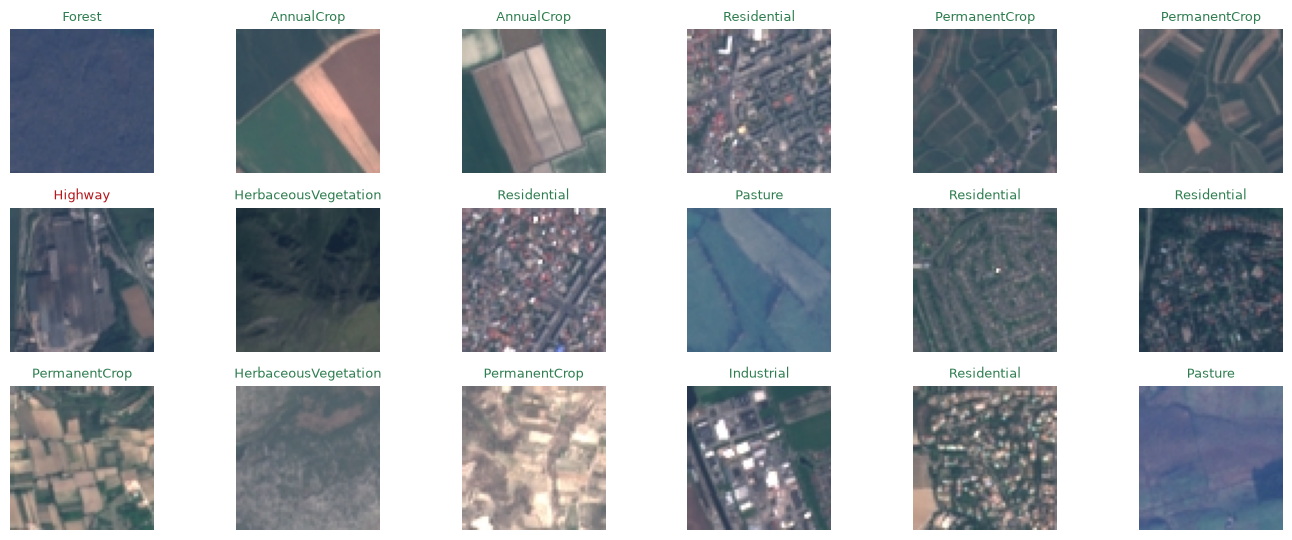

In [16]:
with torch.no_grad():
    previstos = classificador(F_teste).argmax(dim=1)

plt.figure(figsize=(14, 5.5))
for i in range(18):
    imagem, rotulo = eurosat_original[ordem[i]]       # as 2 000 primeiras da ordem são o teste
    plt.subplot(3, 6, i + 1)
    plt.imshow(imagem); plt.axis("off")
    cor = VERDE if previstos[i] == rotulo else VERMELHO
    plt.title(nomes[previstos[i]], color=cor, fontsize=9)
plt.tight_layout(); plt.show()

> **Na prática, em Engenharia de Produção:** para criar um sistema de inspeção visual (peça boa × peça com defeito, tipo de defeito, etc.), o caminho mais comum é exatamente este: partir de uma rede pré-treinada e treinar apenas a parte final com algumas centenas de fotos da sua linha de produção.

---
## Exercícios
---

**1.** Na Seção 3, teste uma rede **comum** com BatchNorm (sem atalho). Dica: crie um bloco igual ao `BlocoResidualBN`, mas com `return correcao` em vez de `return x + correcao`. A BatchNorm sozinha resolve o problema das 50 camadas?

**2.** Na Seção 5, use 200 imagens de treino em vez de 1 000 (troque `ordem[2000:3000]` por `ordem[2000:2200]`). Como fica a comparação entre a CNN do zero e a ResNet pré-treinada?

**3.** Ainda na Seção 5, troque a ResNet-18 pela ResNet-50: `models.resnet50(weights=models.ResNet50_Weights.DEFAULT)`. Atenção: ela devolve vetores de **2048** números, então o classificador deve ser `nn.Linear(2048, 10)`. A acurácia melhora?

**4.** Quais classes a ResNet mais confunde? Use `confusion_matrix` do scikit-learn (Aula 06) com `Y_teste_sat` e `previstos`.